In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (GradientBoostingClassifier, AdaBoostClassifier)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import (precision_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42

In [17]:

df = pd.read_csv("../data/clean/selected_features.csv", sep=",")
display(df.head())
print(f"\nThe shape is: {df.shape}")
print(f"\nThe columns are: {df.columns}")

,application_mode_group,course_name,prev_qual_level,debtor,tuition_fees_up_to_date,gender,scholarship_holder,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_1st_sem_grade,age_at_enrollment,admission_grade,target
0,2nd phase - general contingent,Animation and Multimedia Design,2,0,1,1,0,0,0,0.000000,0.000000,20,127.3,Dropout
1,International student (bachelor),Tourism,2,0,0,1,0,6,6,13.666667,14.000000,19,142.5,Graduate
2,1st phase - general contingent,Communication Design,2,0,0,1,0,6,0,0.000000,0.000000,19,124.8,Dropout
3,2nd phase - general contingent,Journalism and Communication,2,0,1,0,0,6,5,12.400000,13.428571,20,119.6,Graduate
4,Over 23 years old,Social Service (evening attendance),2,0,1,0,0,6,6,13.000000,12.333333,45,141.5,Graduate



The shape is: (3630, 14)

The columns are: Index(['application_mode_group', 'course_name', 'prev_qual_level', 'debtor',
       'tuition_fees_up_to_date', 'gender', 'scholarship_holder',
       'curricular_units_2nd_sem_enrolled',
       'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade',
       'curricular_units_1st_sem_grade', 'age_at_enrollment',
       'admission_grade', 'target'],
      dtype='str')


In [18]:
#Check for enrolled students
df["target"].unique()

<StringArray>
['Dropout', 'Graduate']
Length: 2, dtype: str

In [19]:
#Save enrolled students for risk prediction
df_enrolled = df[df["target"] == "Enrolled"].copy()

#Exclude enrolled students from training
df = df[df["target"] != "Enrolled"].copy()

In [20]:
df["target"].unique()

<StringArray>
['Dropout', 'Graduate']
Length: 2, dtype: str

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (GradientBoostingClassifier, AdaBoostClassifier)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import (precision_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42

In [22]:
#SPLIT THE DATA FRAME (PLACEHOLDER)
X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y
)

In [31]:
nominal_features = ['application_mode_group', 'course_name']

ordinal_features = ["prev_qual_level"]

binary_features = ["debtor", "tuition_fees_up_to_date", "gender", "scholarship_holder"]

numerical_features = [
    "admission_grade",
    "age_at_enrollment",
    "curricular_units_2nd_sem_enrolled",
    "curricular_units_2nd_sem_approved",
    "curricular_units_2nd_sem_grade"
    "curricular_units_1st_sem_grade"
]

In [32]:
ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaling", MinMaxScaler()),
])
nominal_pipeline = Pipeline([("encoding", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
numerical_pipeline = Pipeline([("scaling", MinMaxScaler())])

In [33]:
# Preprocessor for column transformation
preprocessor = ColumnTransformer([
    ("ordinal", ordinal_pipeline, ordinal_features),
    ("nominal", nominal_pipeline, nominal_features),
    ("numerical", numerical_pipeline, numerical_features),
    ("binary", "passthrough", binary_features),
])

In [34]:
# GradientBoostingClassifier taken from sklearn
# Without tuning, using fixed values.
N_ESTIMATORS = 60 # fixed
gradient_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", GradientBoostingClassifier(
        n_estimators=60, 
        learning_rate=0.1,
        max_depth=2, 
        random_state=RANDOM_STATE
    ))
])

gradient_pipeline.fit(X_train, y_train)

ValueError: Some column names are not columns of the dataframe: {'curricular_units_2nd_sem_gradecurricular_units_1st_sem_grade'}

In [ ]:
# Check Training vs Test Accuracy
print("Training accuracy:", round(gradient_pipeline.score(X_train, y_train), 3))
print("Test accuracy:", round(gradient_pipeline.score(X_test, y_test), 3))

In [35]:
# evaluate_classifier function with the classification metrics

results = []

def evaluate_classifier(name, fitted_pipeline):
    """Record Recall, Precision, F1 for a fitted pipeline."""
    pred_train = fitted_pipeline.predict(X_train)
    pred_test = fitted_pipeline.predict(X_test)
    scores = {
        "Model": name,
        "Dropout recall": recall_score(y_test, pred_test, pos_label="Dropout"),
        "Dropout precision": precision_score(y_test, pred_test, pos_label="Dropout"),
        "Dropout F1": f1_score(y_test, pred_test, pos_label="Dropout"),

    }
    results.append(scores)
    return pd.Series(scores)

In [36]:
evaluate_classifier("Gradient Boosting", gradient_pipeline)

NotFittedError: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

In [37]:
# Confusion matrix for both train and test data without tuning the parameters

y_pred_train_gb = gradient_pipeline.predict(X_train)
y_pred_test_gb = gradient_pipeline.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train, y_pred_train_gb,
    labels=["Dropout", "Graduate"], cmap="Blues", ax=axes[0]
)
axes[0].set_title("GradientBoosting Classification (w/o tuning): Train")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test_gb,
    labels=["Dropout", "Graduate"], cmap="Blues", ax=axes[1]
)
axes[1].set_title("GradientBoosting Classification (w/o tuning): Test")
plt.show()

NotFittedError: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

### Hyperparameter tunig using grid search for the Gradient boosting model

In [105]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score

In [106]:

pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", GradientBoostingClassifier(random_state=RANDOM_STATE,
                                         max_depth=2,  # Fixed: keep individual boosting trees shallow.
                                        ))
])

param_grid = {
        "model__n_estimators": [30,50,70,99],  # Integers from 30 to 100
        "model__learning_rate": [0.05,0.1,0.14,0.19], # Numbers from 0.05 to 0.20
}

dropout_f1 = make_scorer(f1_score, pos_label="Dropout")

#  4 estimators × 4 learning rate = 16 configurations; 4 folds = 64 CV fits.
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring= dropout_f1,
    cv=4,
    refit=True,
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)

print("Best hyperparameters:", grid_search.best_params_)
print(f"Best mean CV Dropout F1 : {grid_search.best_score_:.3f}")


Best hyperparameters: {'model__learning_rate': 0.19, 'model__n_estimators': 70}
Best mean CV Dropout F1 : 0.877


In [107]:
# Check the model with the best hyperparameters with the test set

best_model = grid_search.best_estimator_
y_pred_test = best_model.predict(X_test)

print("Test Dropout recall:", round(recall_score(y_test, y_pred_test, pos_label="Dropout"), 3))
print(classification_report(y_test, y_pred_test))

Test Dropout recall: 0.82
              precision    recall  f1-score   support

     Dropout       0.92      0.82      0.87       284
    Graduate       0.89      0.95      0.92       442

    accuracy                           0.90       726
   macro avg       0.91      0.89      0.90       726
weighted avg       0.90      0.90      0.90       726



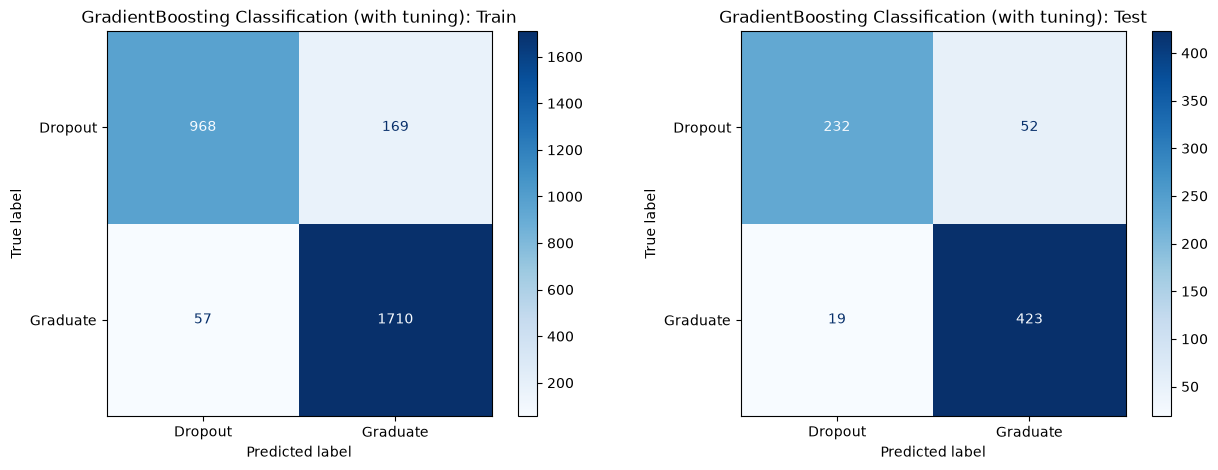

In [136]:
# Confusion matrix for both train and test data with tuning the parameters

y_pred_train_gb = winner_pipeline.predict(X_train)
y_pred_test_gb = winner_pipeline.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train, y_pred_train_gb,
    labels=["Dropout", "Graduate"], cmap="Blues", ax=axes[0]
)
axes[0].set_title("GradientBoosting Classification (with tuning): Train")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test_gb,
    labels=["Dropout", "Graduate"], cmap="Blues", ax=axes[1]
)
axes[1].set_title("GradientBoosting Classification (with tuning): Test")
plt.show()

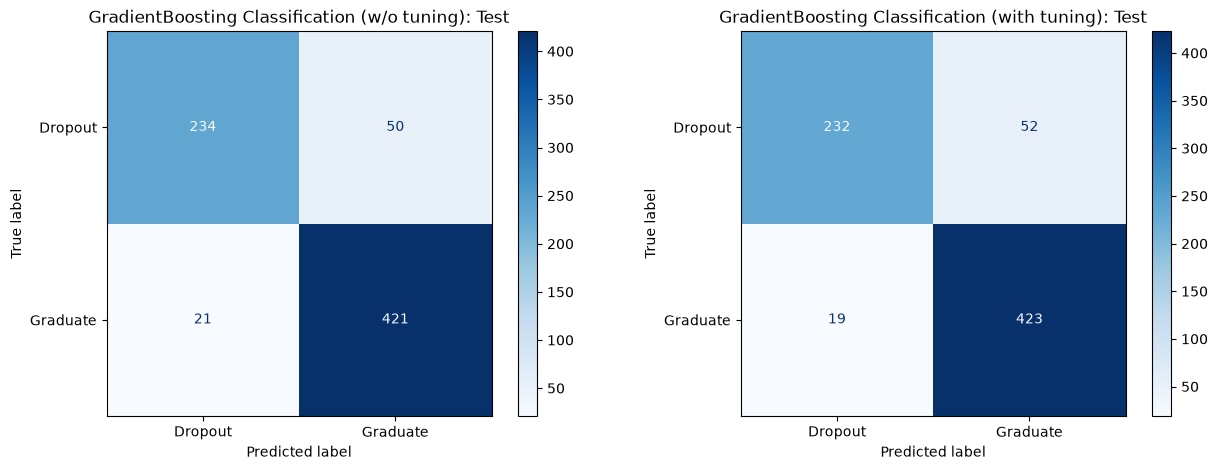

In [139]:
# Confusion matrix for test data with and without tuning the parameters

y_pred_test_gb = gradient_pipeline.predict(X_test)
y_pred_test_gb_tuned = winner_pipeline.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test_gb,
    labels=["Dropout", "Graduate"], cmap="Blues", ax=axes[0]
)
axes[0].set_title("GradientBoosting Classification (w/o tuning): Test")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test_gb_tuned,
    labels=["Dropout", "Graduate"], cmap="Blues", ax=axes[1]
)
axes[1].set_title("GradientBoosting Classification (with tuning): Test")
plt.show()

### Gradient Boosting – confusion matrices without vs with tuning

Test data:
- Without tuning: 234 of 284 dropouts found, 50 missed, 21 false alarms.
- With tuning: 232 of 284 dropouts found, 52 missed, 19 false alarms.
- Accuracy is 0.902 in both cases, so tuning did not change the results on new students.

Train data:
- With tuning, the model makes fewer mistakes on the training data
  (missed dropouts 191 → 169, false alarms 83 → 57, accuracy 0.906 → 0.922).
- But this did not carry over to the test data, so tuning made the model fit the training
  students more closely without improving it for new students (slightly more overfitting).

Conclusion: our starting settings were already close to the best. Since the untuned model finds
slightly more dropouts and is simpler, it is an equally good choice as the final model.

## Apply to df_enrolled – Gradient Boosting

Enrolled students are still studying, so their final outcome is not known yet.
We used the final Gradient Boosting model to predict which of them are at risk of dropping out.

In [108]:
# Import df_enrolled
df_enrolled = pd.read_csv("../data/clean/enrolled_selected_features.csv", sep=",")

display(df.head())
print(f"\nThe shape is: {df.shape}")
print(f"\nThe columns are: {df.columns}")

,application_mode_group,course_name,prev_qual_level,debtor,tuition_fees_up_to_date,gender,scholarship_holder,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,age_at_enrollment,admission_grade,target
0,2nd phase - general contingent,Animation and Multimedia Design,2,0,1,1,0,0,0,0.000000,20,127.3,Dropout
1,International student (bachelor),Tourism,2,0,0,1,0,6,6,13.666667,19,142.5,Graduate
2,1st phase - general contingent,Communication Design,2,0,0,1,0,6,0,0.000000,19,124.8,Dropout
3,2nd phase - general contingent,Journalism and Communication,2,0,1,0,0,6,5,12.400000,20,119.6,Graduate
4,Over 23 years old,Social Service (evening attendance),2,0,1,0,0,6,6,13.000000,45,141.5,Graduate



The shape is: (3630, 13)

The columns are: Index(['application_mode_group', 'course_name', 'prev_qual_level', 'debtor',
       'tuition_fees_up_to_date', 'gender', 'scholarship_holder',
       'curricular_units_2nd_sem_enrolled',
       'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade',
       'age_at_enrollment', 'admission_grade', 'target'],
      dtype='str')


In [109]:
print(grid_search.best_params_)
final_gb = grid_search.best_estimator_

{'model__learning_rate': 0.19, 'model__n_estimators': 70}


In [110]:
# Predict with the final Gradient Boosting model
X_enrolled = df_enrolled.copy()
y_pred_enrolled_gb = final_gb.predict(X_enrolled)

In [111]:
df_enrolled["predicted_status"] = y_pred_enrolled_gb

In [142]:
print(df_enrolled["predicted_status"].value_counts())

predicted_status
Graduate    451
Dropout     343
Name: count, dtype: int64


In [141]:
#Dropout probability for each enrolled student using predictproba

dropout_col = list(final_gb.classes_).index("Dropout")

df_enrolled["dropout_risk"] = final_gb.predict_proba(X_enrolled)[:, dropout_col].round(3)

In [143]:
# Students with the highest risk 

df_enrolled.sort_values("dropout_risk", ascending=False).head(10)

,application_mode_group,course_name,prev_qual_level,debtor,tuition_fees_up_to_date,gender,scholarship_holder,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,age_at_enrollment,admission_grade,predicted_status,dropout_risk
156,2nd phase - general contingent,Informatics Engineering,2,1,0,1,0,5,0,0.0,18,120.4,Dropout,0.998
553,Transfer / change,Informatics Engineering,2,1,0,1,0,5,0,0.0,27,128.0,Dropout,0.998
29,Transfer / change,Management,2,1,0,0,0,5,0,0.0,22,99.7,Dropout,0.997
390,Over 23 years old,Veterinary Nursing,1,1,0,1,0,6,0,0.0,25,138.3,Dropout,0.997
19,Transfer / change,Informatics Engineering,2,1,1,1,0,5,0,0.0,18,112.2,Dropout,0.996
267,Prior qualification,Equinculture,3,1,0,0,0,6,2,11.0,20,140.0,Dropout,0.995
645,Over 23 years old,Nursing,0,0,1,1,0,7,0,0.0,33,100.0,Dropout,0.994
162,Over 23 years old,Veterinary Nursing,2,1,1,0,0,6,0,0.0,28,129.3,Dropout,0.993
134,International student (bachelor),Management,2,1,1,1,0,5,1,10.0,40,100.0,Dropout,0.993
414,Over 23 years old,Informatics Engineering,2,1,1,1,0,5,1,11.0,24,110.3,Dropout,0.992


## Comparing AdaBoostClassifier and GradientBoostingClassifier CrossValidation by using GridSearch

In [119]:

# Step 1 — Define two different ensemble strategies.
candidates = {
    "AdaBoost" : Pipeline([
    ("preprocess", preprocessor),
    ("model", AdaBoostClassifier(
        random_state=RANDOM_STATE,
    )),
])
,
    "Gradient Boosting": Pipeline([
        ("preprocess", preprocessor),
        ("model", GradientBoostingClassifier(
            random_state=RANDOM_STATE,
            max_depth=2,  # Fixed: keep individual boosting trees shallow.
        ))
    ]),
}

# Step 2 — Choose exactly TWO values for each hyperparameter.
# Stay within the ranges in the table above. Do not use max_depth=None.
# Each model should have 2 x 2 = 4 combinations.
parameter_grids = {
    "AdaBoost": {
        "model__n_estimators": [30,90],  # Integers from 30 to 100
        "model__learning_rate": [0.05,0.15],      
    },
    "Gradient Boosting": {
        "model__n_estimators": [30,70],  # Integers from 30 to 100
        "model__learning_rate": [0.1,0.2], # Numbers from 0.05 to 0.20
    },
}


In [120]:
# Step 3 — Tune each pipeline on the TRAINING set only.


searches = {}

for name, candidate_pipeline in candidates.items():
    search = GridSearchCV(
        estimator=candidate_pipeline,
        param_grid=parameter_grids[name],
        scoring=dropout_f1,
        cv=4,
        refit=True,
        n_jobs= -1,  # Avoid nested parallelism (Random Forest uses n_jobs=-1).
    )
    search.fit(X_train, y_train)
    searches[name] = search

# Step 4 — Compare best CV scores (Higher F1 is better).
# TODO: uncomment after running the searches.
cv_comparison = pd.DataFrame([
    {"Model": name, "Best CV F1": search.best_score_,
      "Best parameters": search.best_params_}
     for name, search in searches.items()
 ]).sort_values("Best CV F1",ascending=False)

pd.set_option("display.max_colwidth", None)

display(cv_comparison)



,Model,Best CV F1,Best parameters
1,Gradient Boosting,0.876987,"{'model__learning_rate': 0.2, 'model__n_estimators': 70}"
0,AdaBoost,0.847471,"{'model__learning_rate': 0.15, 'model__n_estimators': 90}"


In [122]:
# Step 5 — Select using CV results, then evaluate ONCE on test.
winner_name = cv_comparison.iloc[0]["Model"]
winner_pipeline = searches[winner_name].best_estimator_
final_predictions = winner_pipeline.predict(X_test)

print("Selected model:", winner_name)
print(f"Final test F1: {f1_score(y_test, final_predictions, pos_label="Dropout"):.3f}")

Selected model: Gradient Boosting
Final test F1: 0.867


### Final model – Gradient Boosting

- Gradient Boosting had the best cross-validation F1 score, so it was selected as the final model.
- On the train set, it reaches an F1 score of 0.867 for the Dropout class:
  it finds most dropout students and most of its dropout alarms are correct.
- This is a clear improvement on our first KNN model (F1 about 0.66).
- The model was chosen using cross-validation on the training data only,
  and the test set was used once at the end, so the result is a fair estimate for new students.